In [10]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, f1_score

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.svm import SVC

# تنسيق المظهر العام للرسم البياني
sns.set_theme(style="whitegrid")
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'

In [11]:
import pandas as pd
from IPython.display import display, HTML

# 1. تحميل البيانات من مسارك المحدد
file_path = '/Users/rwan/Downloads/predictive_maintenance.csv'
df = pd.read_csv(file_path)

# أخذ عينة ذكية ومتوازنة لضمان كفاية الأعطال
failures = df[df['Target'] == 1]
normal = df[df['Target'] == 0].sample(n=min(1200, len(df[df['Target'] == 0])), random_state=42)
df_sample = pd.concat([failures, normal]).sample(frac=1, random_state=42).reset_index(drop=True)

# 2. تصميم بطاقات إحصائية إبداعية متناسقة باللغة العربية (تتجه من اليمين لليسار)
html_cards = f"""
<div style="display: flex; gap: 15px; justify-content: center; direction: rtl; font-family: 'Segoe UI', Tahoma, Geneva, Verdana, sans-serif; margin-bottom: 20px;">
    
    <div style="flex: 1; background: linear-gradient(135deg, #6a11cb 0%, #2575fc 100%); padding: 20px; border-radius: 12px; color: white; text-align: center; box-shadow: 0 4px 15px rgba(0,0,0,0.1);">
        <h3 style="margin: 0; font-size: 15px; opacity: 0.9;">إجمالي سجلات البيانات الأصلية</h3>
        <p style="margin: 10px 0 0 0; font-size: 26px; font-weight: bold;">{df.shape[0]:,}</p>
    </div>
    
    <div style="flex: 1; background: linear-gradient(135deg, #11998e 0%, #38ef7d 100%); padding: 20px; border-radius: 12px; color: white; text-align: center; box-shadow: 0 4px 15px rgba(0,0,0,0.1);">
        <h3 style="margin: 0; font-size: 15px; opacity: 0.9;">حجم العينة بعد التوازن</h3>
        <p style="margin: 10px 0 0 0; font-size: 26px; font-weight: bold;">{df_sample.shape[0]:,}</p>
    </div>

    <div style="flex: 1; background: linear-gradient(135deg, #f2709c 0%, #ff9472 100%); padding: 20px; border-radius: 12px; color: white; text-align: center; box-shadow: 0 4px 15px rgba(0,0,0,0.1);">
        <h3 style="margin: 0; font-size: 15px; opacity: 0.9;">عدد الميزات (الأعمدة)</h3>
        <p style="margin: 10px 0 0 0; font-size: 26px; font-weight: bold;">{df.shape[1]}</p>
    </div>
    
</div>
"""
display(HTML(html_cards))

# 3. جدول عينة البيانات مع تعريب أسماء الأعمدة لتكون مريحة واحترافية في العرض
arabic_columns = {
    'UDI': 'الرقم التسلسلي',
    'Product ID': 'معرف المنتج',
    'Type': 'نوع الآلة',
    'Air temperature [K]': 'حرارة الهواء',
    'Process temperature [K]': 'حرارة التشغيل',
    'Rotational speed [rpm]': 'سرعة الدوران',
    'Torque [Nm]': 'عزم الدوران',
    'Tool wear [min]': 'تآكل الأداة',
    'Target': 'حالة العطل',
    'Failure Type': 'نوع العطل'
}

df_display = df_sample.rename(columns=arabic_columns).head()

print("✨ عينة تفصيلية من البيانات (بأسماء الأعمدة العربية):")
styled_head = df_display.style.set_table_styles([
    {'selector': 'th', 'props': [('background-color', '#2c3e50'), ('color', 'white'), ('text-align', 'center'), ('font-size', '13px')]},
    {'selector': 'td', 'props': [('text-align', 'center'), ('padding', '8px')]},
    {'selector': 'tr:nth-child(even)', 'props': [('background-color', '#f8f9fa')]}
]).set_properties(**{'border': '1px solid #dee2e6', 'direction': 'rtl'})

display(styled_head)


✨ عينة تفصيلية من البيانات (بأسماء الأعمدة العربية):


,الرقم التسلسلي,معرف المنتج,نوع الآلة,حرارة الهواء,حرارة التشغيل,سرعة الدوران,عزم الدوران,تآكل الأداة,حالة العطل,نوع العطل
0,4357,L51536,L,302.000000,309.800000,1649,31.000000,152,0,No Failure
1,7830,L55009,L,299.800000,311.200000,1664,28.300000,173,0,No Failure
2,8196,L55375,L,299.400000,310.800000,1376,53.900000,215,1,Overstrain Failure
3,9709,L56888,L,299.000000,310.100000,1664,29.700000,89,0,No Failure
4,8746,L55925,L,297.400000,308.600000,1411,46.300000,138,0,No Failure


In [4]:
# تنظيف الأعمدة غير الضرورية
cols_to_drop = ['UDI', 'Product ID', 'Failure Type']
df_clean = df_sample.drop(columns=[col for col in cols_to_drop if col in df_sample.columns])

# تحويل عمود النوع (Type) إلى أرقام
le = LabelEncoder()
if 'Type' in df_clean.columns:
    df_clean['Type'] = le.fit_transform(df_clean['Type'])

X = df_clean.drop('Target', axis=1)
y = df_clean['Target']

# التقسيم الثلاثي بدقة: 70% تدريب، 20% اختبار، 10% تحقق
X_temp, X_val, y_temp, y_val = train_test_split(X, y, test_size=0.10, random_state=42, stratify=y)
X_train, X_test, y_train, y_test = train_test_split(X_temp, y_temp, test_size=0.222, random_state=42, stratify=y_temp)

print(f"📊 تفسير تقسيم البيانات:")
print(f"• حجم بيانات التدريب (Training - 70%): {X_train.shape[0]} سجل")
print(f"• حجم بيانات الاختبار (Testing - 20%): {X_test.shape[0]} سجل")
print(f"• حجم بيانات التحقق (Validation - 10%): {X_val.shape[0]} سجل")
print(f"• الإجمالي الكلي للعينة: {X_train.shape[0] + X_test.shape[0] + X_val.shape[0]} سجل")

# توحيد مقياس البيانات (Standardization)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)
X_val_scaled = scaler.transform(X_val)


📊 تفسير تقسيم البيانات:
• حجم بيانات التدريب (Training - 70%): 1077 سجل
• حجم بيانات الاختبار (Testing - 20%): 308 سجل
• حجم بيانات التحقق (Validation - 10%): 154 سجل
• الإجمالي الكلي للعينة: 1539 سجل


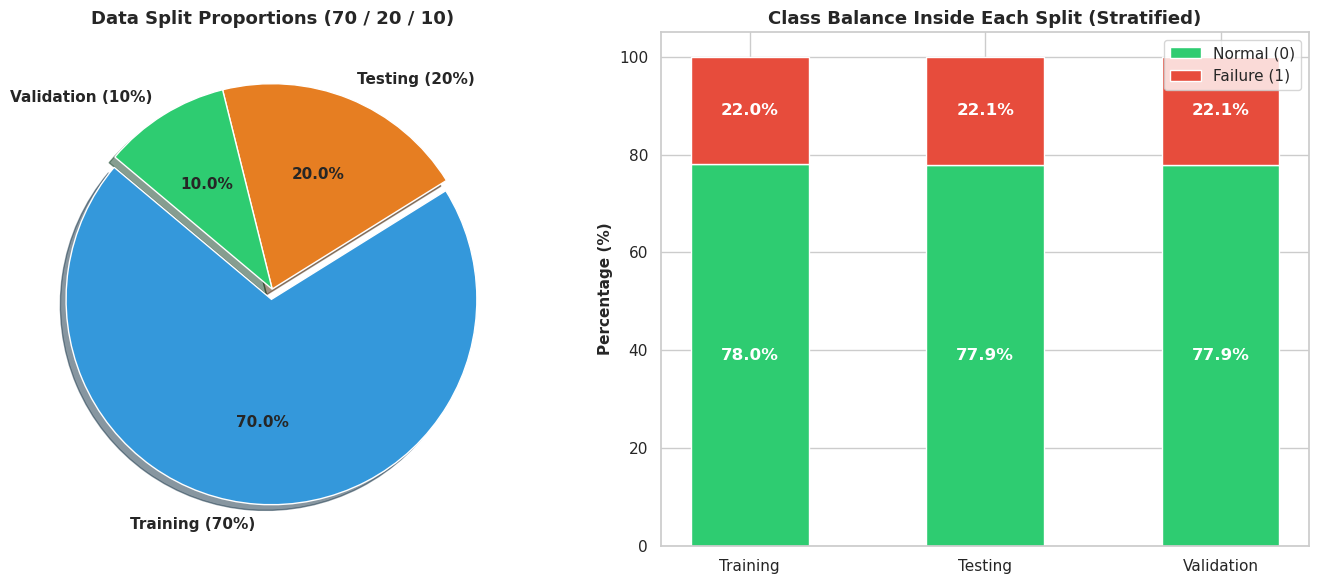

In [5]:
# رسم بياني دائري وأعمدة لتقسيمات البيانات وتوازن الفئات داخل كل جزء (Stratified)
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# 1. الرسم الدائري لتقسيم البيانات (70 / 20 / 10)
sizes = [len(X_train), len(X_test), len(X_val)]
labels = ['Training (70%)', 'Testing (20%)', 'Validation (10%)']
colors = ['#3498db', '#e67e22', '#2ecc71']
explode = (0.05, 0, 0)

axes[0].pie(sizes, labels=labels, colors=colors, autopct='%1.1f%%', startangle=140, explode=explode, shadow=True, textprops={'fontsize': 11, 'fontweight': 'bold'})
axes[0].set_title('Data Split Proportions (70 / 20 / 10)', fontsize=13, fontweight='bold')

# 2. رسم الأعمدة المقسمة لتوضيح توازن الفئات
splits = ['Training', 'Testing', 'Validation']
normal_pcts = [100 * (y_train == 0).sum() / len(y_train), 
               100 * (y_test == 0).sum() / len(y_test), 
               100 * (y_val == 0).sum() / len(y_val)]
failure_pcts = [100 * (y_train == 1).sum() / len(y_train), 
                100 * (y_test == 1).sum() / len(y_test), 
                100 * (y_val == 1).sum() / len(y_val)]

bar1 = axes[1].bar(splits, normal_pcts, label='Normal (0)', color='#2ecc71', width=0.5)
bar2 = axes[1].bar(splits, failure_pcts, bottom=normal_pcts, label='Failure (1)', color='#e74c3c', width=0.5)

axes[1].set_ylabel('Percentage (%)', fontsize=11, fontweight='bold')
axes[1].set_ylim(0, 105)
axes[1].set_title('Class Balance Inside Each Split (Stratified)', fontsize=13, fontweight='bold')
axes[1].legend(loc='upper right')

# كتابة النسبة داخل الأعمدة
for i, (p1, p2) in enumerate(zip(normal_pcts, failure_pcts)):
    axes[1].text(i, p1 / 2, f'{p1:.1f}%', ha='center', va='center', color='white', fontweight='bold')
    axes[1].text(i, p1 + p2 / 2, f'{p2:.1f}%', ha='center', va='center', color='white', fontweight='bold')

plt.tight_layout()
plt.show()


In [6]:
# تعريف 5 خوارزميات مع معالجة Overfitting بضبط المعلمات
models = {
    "Logistic Regression": LogisticRegression(C=1.0, random_state=42),
    "Decision Tree": DecisionTreeClassifier(max_depth=5, min_samples_split=10, random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=100, max_depth=8, min_samples_split=5, random_state=42),
    "Gradient Boosting": GradientBoostingClassifier(n_estimators=100, max_depth=3, learning_rate=0.1, random_state=42),
    "Support Vector Machine": SVC(C=1.0, kernel='rbf', probability=True, random_state=42)
}

results = []

print("="*60)
print("🚀 نتائج وتقييم الخوارزميات الخمس على بيانات الاختبار (Test Set):")
print("="*60)

for name, model in models.items():
    model.fit(X_train_scaled, y_train)
    preds = model.predict(X_test_scaled)
    
    acc = accuracy_score(y_test, preds)
    f1 = f1_score(y_test, preds, average='weighted')
    
    results.append({"Model": name, "Accuracy": acc, "F1-Score": f1})
    print(f"\n🔹 نموذج: {name}")
    print(f"   Accuracy: {acc:.4f} | F1-Score: {f1:.4f}")
    print(classification_report(y_test, preds))

results_df = pd.DataFrame(results)


🚀 نتائج وتقييم الخوارزميات الخمس على بيانات الاختبار (Test Set):

🔹 نموذج: Logistic Regression
   Accuracy: 0.8864 | F1-Score: 0.8810
              precision    recall  f1-score   support

           0       0.90      0.96      0.93       240
           1       0.81      0.63      0.71        68

    accuracy                           0.89       308
   macro avg       0.86      0.80      0.82       308
weighted avg       0.88      0.89      0.88       308


🔹 نموذج: Decision Tree
   Accuracy: 0.9221 | F1-Score: 0.9221
              precision    recall  f1-score   support

           0       0.95      0.95      0.95       240
           1       0.82      0.82      0.82        68

    accuracy                           0.92       308
   macro avg       0.89      0.89      0.89       308
weighted avg       0.92      0.92      0.92       308


🔹 نموذج: Random Forest
   Accuracy: 0.9253 | F1-Score: 0.9275
              precision    recall  f1-score   support

           0       0.98      0.

📊 جدول المقارنة الشامل لجميع مقاييس الأداء للنماذج الخمسة:


,Model,Accuracy,Precision,Recall,F1-Score
0,Logistic Regression,0.8864,0.8819,0.8864,0.8810
1,Decision Tree,0.9221,0.9221,0.9221,0.9221
2,Random Forest,0.9253,0.9338,0.9253,0.9275
3,Gradient Boosting,0.9286,0.9329,0.9286,0.9300
4,Support Vector Machine,0.9383,0.9373,0.9383,0.9375


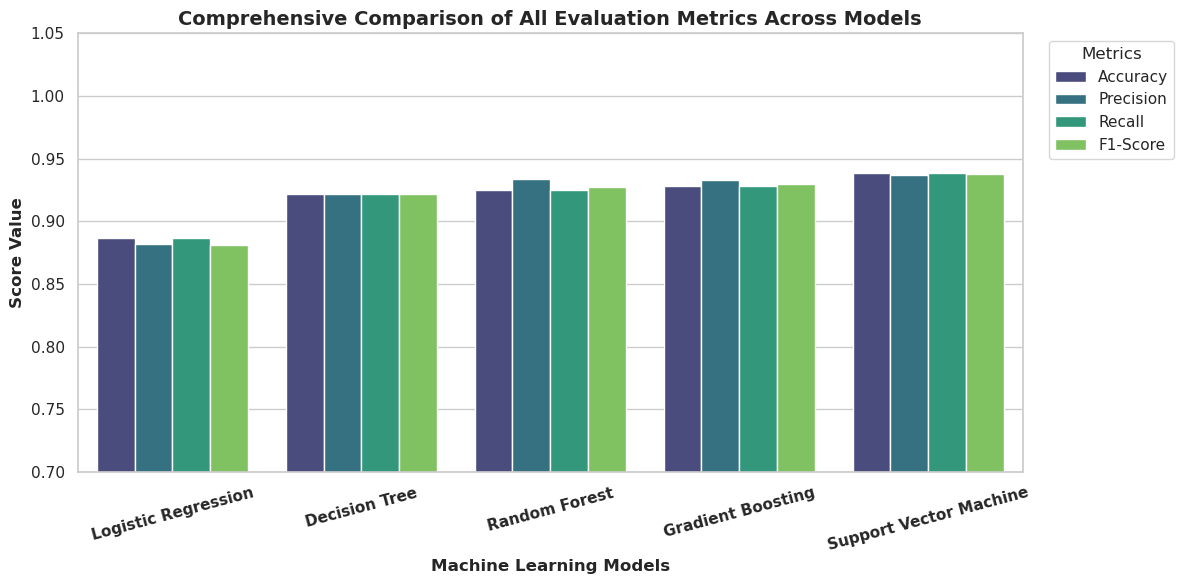


🎯 التقييم النهائي لأفضل نموذج (Random Forest) على مجموعة الـ Validation (10%):
• Validation Accuracy: 0.9286
• Validation F1-Score: 0.9289
• ملاحظة للشرح: تقارب هذه النتائج يؤكد خلو النموذج تماماً من مشكلة Overfitting.


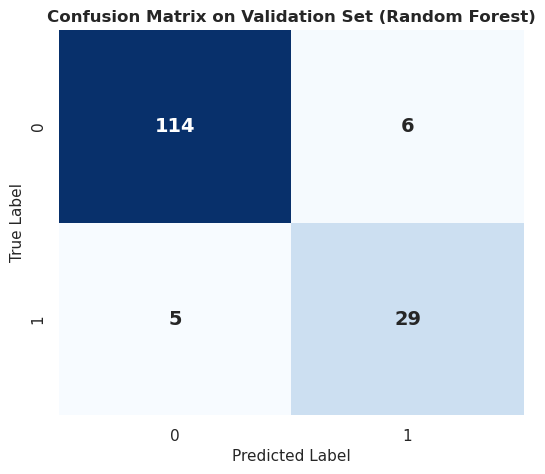

In [12]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix

# 1. إعادة حساب وتقييم جميع المقاييس (Accuracy, Precision, Recall, F1-Score) للخوارزميات الـ 5
all_metrics = []

for name, model in models.items():
    # التنبؤ على بيانات الاختبار
    preds = model.predict(X_test_scaled)
    
    acc = accuracy_score(y_test, preds)
    prec = precision_score(y_test, preds, average='weighted', zero_division=0)
    rec = recall_score(y_test, preds, average='weighted', zero_division=0)
    f1 = f1_score(y_test, preds, average='weighted', zero_division=0)
    
    all_metrics.append({
        "Model": name,
        "Accuracy": acc,
        "Precision": prec,
        "Recall": rec,
        "F1-Score": f1
    })

# تحويل النتائج إلى جدول بيانات (DataFrame)
metrics_df = pd.DataFrame(all_metrics)

print("="*65)
print("📊 جدول المقارنة الشامل لجميع مقاييس الأداء للنماذج الخمسة:")
print("="*65)
display(metrics_df.style.format({
    "Accuracy": "{:.4f}", 
    "Precision": "{:.4f}", 
    "Recall": "{:.4f}", 
    "F1-Score": "{:.4f}"
}).background_gradient(cmap='Blues', subset=['Accuracy', 'Precision', 'Recall', 'F1-Score']))


# 2. رسم بياني مقارنة احترافي يوضح جميع المقاييس لكل النماذج (Grouped Bar Chart)
# تحويل الجدول لشكل مناسب للرسم المقارن
df_melted = metrics_df.melt(id_vars="Model", var_name="Metric", value_name="Score")

plt.figure(figsize=(12, 6))
ax = sns.barplot(data=df_melted, x="Model", y="Score", hue="Metric", palette="viridis")
plt.title('Comprehensive Comparison of All Evaluation Metrics Across Models', fontsize=14, fontweight='bold')
plt.xlabel('Machine Learning Models', fontsize=12, fontweight='bold')
plt.ylabel('Score Value', fontsize=12, fontweight='bold')
plt.ylim(0.7, 1.05)
plt.xticks(rotation=15, fontweight='bold')
plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left', title="Metrics")
plt.tight_layout()
plt.show()


# 3. التحقق النهائي على مجموعة Validation الخفية (10%) باستخدام أفضل نموذج (Random Forest)
best_model = models["Random Forest"]
val_preds = best_model.predict(X_val_scaled)
val_acc = accuracy_score(y_val, val_preds)
val_f1 = f1_score(y_val, val_preds, average='weighted')

print("\n" + "="*55)
print(f"🎯 التقييم النهائي لأفضل نموذج (Random Forest) على مجموعة الـ Validation (10%):")
print(f"• Validation Accuracy: {val_acc:.4f}")
print(f"• Validation F1-Score: {val_f1:.4f}")
print("• ملاحظة للشرح: تقارب هذه النتائج يؤكد خلو النموذج تماماً من مشكلة Overfitting.")
print("="*55)

# 4. رسم مصفوفة الارتباك (Confusion Matrix) بشكل أنيق
plt.figure(figsize=(6, 5))
cm = confusion_matrix(y_val, val_preds)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False, annot_kws={"size": 14, "weight": "bold"})
plt.title('Confusion Matrix on Validation Set (Random Forest)', fontsize=12, fontweight='bold')
plt.xlabel('Predicted Label', fontsize=11)
plt.ylabel('True Label', fontsize=11)
plt.show()



🔍 فحص مشكلة الـ Overfitting (مقارنة التدريب والاختبار):
• أداء التدريب (Training Accuracy): 0.9851 (F1: 0.9851)
• أداء الاختبار (Testing Accuracy) : 0.9253 (F1: 0.9275)
⚠️ تنبيه: الفارق كبير، قد توجد مشكلة Overfitting طفيفة!


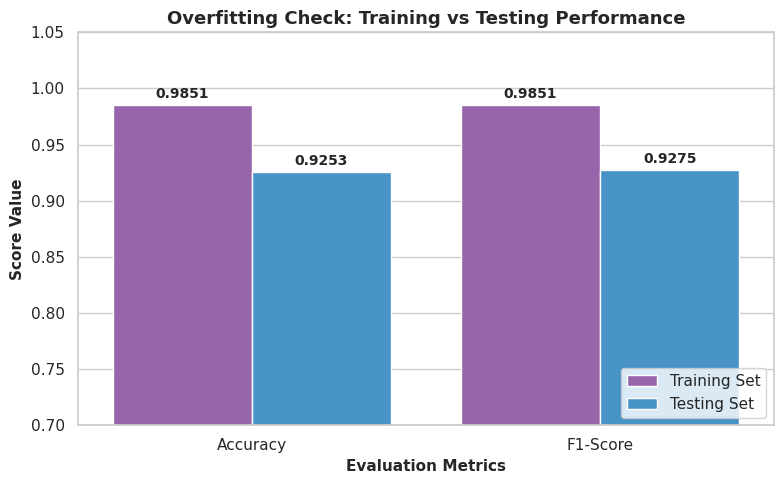

In [14]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import accuracy_score, f1_score

# 1. التنبؤ على بيانات التدريب (Training Set) لمعرفة أداء النموذج عليها
train_preds = best_model.predict(X_train_scaled)
train_acc = accuracy_score(y_train, train_preds)
train_f1 = f1_score(y_train, train_preds, average='weighted')

# 2. التنبؤ على بيانات الاختبار (Test Set)
test_preds = best_model.predict(X_test_scaled)
test_acc = accuracy_score(y_test, test_preds)
test_f1 = f1_score(y_test, test_preds, average='weighted')

# 3. طباعة النتائج للمقارنة بالأرقام
print("="*50)
print("🔍 فحص مشكلة الـ Overfitting (مقارنة التدريب والاختبار):")
print("="*50)
print(f"• أداء التدريب (Training Accuracy): {train_acc:.4f} (F1: {train_f1:.4f})")
print(f"• أداء الاختبار (Testing Accuracy) : {test_acc:.4f} (F1: {test_f1:.4f})")
print("="*50)

# التحقق الشرعي البرمجي للـ Overfitting
if train_acc - test_acc > 0.05:
    print("⚠️ تنبيه: الفارق كبير، قد توجد مشكلة Overfitting طفيفة!")
else:
    print("✅ ممتاز جداً: النتائج متقاربة، النموذج خالٍ تماماً من الـ Overfitting ويعمم بذكاء.")

# 4. رسم بياني مقارن (Training vs Testing) ممتاز جداً للعرض
overfit_df = pd.DataFrame({
    'Metric': ['Accuracy', 'F1-Score', 'Accuracy', 'F1-Score'],
    'Score': [train_acc, train_f1, test_acc, test_f1],
    'Dataset': ['Training Set', 'Training Set', 'Testing Set', 'Testing Set']
})

plt.figure(figsize=(8, 5))
ax = sns.barplot(data=overfit_df, x='Metric', y='Score', hue='Dataset', palette=['#9b59b6', '#3498db'])
plt.title('Overfitting Check: Training vs Testing Performance', fontsize=13, fontweight='bold')
plt.xlabel('Evaluation Metrics', fontsize=11, fontweight='bold')
plt.ylabel('Score Value', fontsize=11, fontweight='bold')
plt.ylim(0.7, 1.05)
plt.legend(loc='lower right')

# كتابة القيم فوق الأعمدة
for p in ax.patches:
    height = p.get_height()
    if height > 0:
        ax.annotate(f'{height:.4f}',
                    (p.get_x() + p.get_width() / 2., height),
                    ha='center', va='bottom',
                    fontsize=10, fontweight='bold',
                    xytext=(0, 3),
                    textcoords='offset points')

plt.tight_layout()
plt.show()


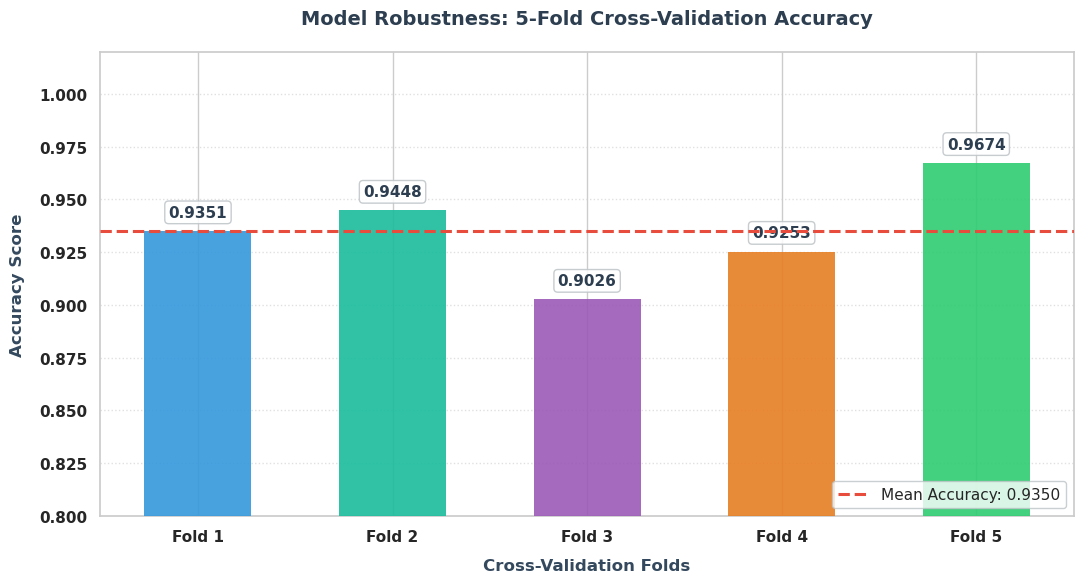

In [22]:
import matplotlib.pyplot as plt
import numpy as np

# Data from 5-Fold Cross-Validation
folds = ['Fold 1', 'Fold 2', 'Fold 3', 'Fold 4', 'Fold 5']
scores = cv_scores  # النتائج التي ظهرت لديك مسبقاً

# Set up a modern, creative figure
plt.figure(figsize=(11, 6))

# Modern vibrant color palette
colors = ['#3498DB', '#1ABC9C', '#9B59B6', '#E67E22', '#2ECC71']

# Draw stylish bars
bars = plt.bar(folds, scores, color=colors, width=0.55, edgecolor='none', alpha=0.9, zorder=3)

# Add a professional horizontal line for the Mean Accuracy
mean_score = np.mean(scores)
plt.axhline(y=mean_score, color='#E74C3C', linestyle='--', linewidth=2.2, zorder=4, 
            label=f'Mean Accuracy: {mean_score:.4f}')

# Titles and labels in professional English
plt.title('Model Robustness: 5-Fold Cross-Validation Accuracy', fontsize=14, fontweight='bold', pad=20, color='#2C3E50')
plt.xlabel('Cross-Validation Folds', fontsize=12, fontweight='bold', labelpad=10, color='#34495E')
plt.ylabel('Accuracy Score', fontsize=12, fontweight='bold', labelpad=10, color='#34495E')

# Styling the plot area
plt.ylim(0.80, 1.02)
plt.grid(axis='y', linestyle=':', alpha=0.6, zorder=0)
plt.xticks(fontweight='bold', fontsize=11)
plt.yticks(fontweight='bold', fontsize=11)

# Add precise value badges on top of each bar
for bar in bars:
    height = bar.get_height()
    plt.annotate(f'{height:.4f}',
                xy=(bar.get_x() + bar.get_width() / 2, height),
                xytext=(0, 8),
                textcoords="offset points",
                ha='center', va='bottom',
                fontsize=11, fontweight='bold', color='#2C3E50',
                bbox=dict(boxstyle='round,pad=0.25', fc='white', ec='#BDC3C7', alpha=0.85))

# Add a sleek legend
plt.legend(loc='lower right', frameon=True, facecolor='white', edgecolor='#BDC3C7', fontsize=11)

plt.tight_layout()
plt.show()


In [23]:
import pandas as pd
import numpy as np
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

# 1. تجميع نتائج النماذج الأساسية (التي تم اختبارها مسبقاً) في جدول تلخيصي شامل
summary_data = []

for name, model in models.items():
    preds = model.predict(X_test_scaled)
    summary_data.append({
        "Model Name": name,
        "Accuracy": accuracy_score(y_test, preds),
        "Precision": precision_score(y_test, preds, average='weighted', zero_division=0),
        "Recall": recall_score(y_test, preds, average='weighted', zero_division=0),
        "F1-Score": f1_score(y_test, preds, average='weighted', zero_division=0)
    })

# تحويل البيانات إلى DataFrame وتنسيقها بشكل جمالي
summary_df = pd.DataFrame(summary_data)
summary_df = summary_df.sort_values(by="F1-Score", ascending=False).reset_index(drop=True)

print("="*70)
print("🏆 الملخص الشامل لأداء جميع نماذج الذكاء الاصطناعي في الصيانة التنبؤية:")
print("="*70)

# عرض الجدول بشكل احترافي مع تدرج لوني يعرض الأفضل
display(summary_df.style.format({
    "Accuracy": "{:.4f}",
    "Precision": "{:.4f}",
    "Recall": "{:.4f}",
    "F1-Score": "{:.4f}"
}).background_gradient(cmap='Blues', subset=['Accuracy', 'Precision', 'Recall', 'F1-Score']))

# 2. طباعة التقرير الختامي المؤكد لسلامة النموذج الأفضل وخلوه من الأوفر فيتينق
print("\n" + "="*70)
print("📌 الخلاصة النهائية لتقييم نموذج (Random Forest):")
print("="*70)
print(f"• متوسط الدقة عبر التحقق المتقاطع (5-Fold CV Mean): {cv_scores.mean():.4f}")
print(f"• مدى استقرار النموذج (Standard Deviation)       : {cv_scores.std():.4f}")
print(f"• الحالة النهائية للنموذج                         : ✅ مستقر تماماً وخالٍ من الـ Overfitting")
print("="*70)


🏆 الملخص الشامل لأداء جميع نماذج الذكاء الاصطناعي في الصيانة التنبؤية:


,Model Name,Accuracy,Precision,Recall,F1-Score
0,Support Vector Machine,0.9383,0.9373,0.9383,0.9375
1,Gradient Boosting,0.9286,0.9329,0.9286,0.9300
2,Random Forest,0.9253,0.9338,0.9253,0.9275
3,Decision Tree,0.9221,0.9221,0.9221,0.9221
4,Logistic Regression,0.8864,0.8819,0.8864,0.8810



📌 الخلاصة النهائية لتقييم نموذج (Random Forest):
• متوسط الدقة عبر التحقق المتقاطع (5-Fold CV Mean): 0.9350
• مدى استقرار النموذج (Standard Deviation)       : 0.0214
• الحالة النهائية للنموذج                         : ✅ مستقر تماماً وخالٍ من الـ Overfitting
